<img src='https://gitlab.eumetsat.int/eumetlab/oceans/ocean-training/tools/frameworks/-/raw/main/img/Standard_banner.png' align='right' width='100%'/>

<font color="#138D75">**WEkEO Training**</font> <br>
**Copyright:** 2024 European Union <br>
**License:** MIT <br>
**Authors:** Anna-Lena Erdmann (EUMETSAT)

<html>
  <div style="width:100%">
    <div style="float:left"><a href="https://jupyterhub.prod.wekeo2.eu/hub/user-redirect/lab/tree/public/wekeo4data/wekeo-eocanvas/03_EOCanvas_DataTailor.ipynb"><img src="https://img.shields.io/badge/launch-WEKEO-1a4696.svg?style=flat&logo=" alt="Open in WEkEO"></a></div>
    <div style="float:left"><p>&emsp;</p></div>
  </div>    
</html>

<div class="alert alert-block alert-success">
<h3> WEkEO EOCanvas - Processing in the Cloud for Coperncius Data</h3></div>

<div class="alert alert-block alert-warning">
    
<b>PREREQUISITES </b>
    
This notebook has the following prerequisites:
  - **<a href="https://my.wekeo.eu/user-registration" target="_blank">A WEkEO account</a>**

  

</div>
<hr>

# 5 Using the EODATA bucket for input to the EOCanvas

### Learning outcomes

At the end of this notebook you will know;

* how to use data within the <a href='https://help.wekeo.eu/en/articles/7146616-how-to-get-direct-access-to-eodata' target='_blank'>EODATA</a> S3 bucket as inout to the EOCanvas functions. 



### Outline

The EOCanvas is a WEkEO service to process Coperncius data in the cloud. The inout to the EOCanvas functions can either come from WEkEOs <a href='https://www.wekeo.eu/docs/harmonised-data-access-api' target='_blank'>Harmonised Data Access (HDA) API</a> or a remote object storage. This notebook provides an example on how to use data in the <a href='https://help.wekeo.eu/en/articles/7146616-how-to-get-direct-access-to-eodata' target='_blank'>EODATA</a> S3 bucket as input to the EOCanvas functions. 

<div class="alert alert-info" role="alert">

### Contents <a id='totop'></a>

</div>
    
 1. [Setting Up the EOCanvas](#section0)
 2. [Connect to EODATA](#section1)
 3. [Execute the EOCanvas Function](#section2)
 4. [Examine the results](#section3)

<hr>

<div class="alert alert-info" role="alert">

## 1. <a id='section0'></a>Setting Up
[Back to top](#totop)
    
</div>

This example notebook shows you how to use the functions of the <a href='https://user.eumetsat.int/resources/user-guides/data-tailor-standalone-guide' target='_blank'>EUMETSAT Data Tailor</a> within the EOCanvas package. If you are a user of the Data Tailor, you can simply reuse your processes chains in the EOCanvas.  

Loadning necessary libraries

In [20]:
import glob

from hda import Client
import xarray as xr
from eocanvas import API, Credentials
from eocanvas.api import Input, Config, ConfigOption
from eocanvas.datatailor.chain import Chain
from eocanvas.processes import DataTailorProcess

You must replace `<your_user_name>` and `<your_password>` with the information from your WEkEO account (if you don't have one yet, register <a href="https://www.wekeo.eu/" target="_blank">here</a>.

Save your credentials. They will be automatically loaded when required.

In [ ]:
c = Credentials(username="<your_user_name>", password="<your_password>")
c.save()

<div class="alert alert-info" role="alert">

## 2. <a id='section1'></a>Inputs to the EOCanvas Data Tailor Process
[Back to top](#totop)
    
</div>



The Data Tailor function takes two necessary inputs: 

- data: we will get the data from the EODATA bucket
- eptc chain: processing workflow of the data tailor inside a .yml file

### 2.1 Data 

The data is given to the serverless function as an **url**. The url is the reference location of the data. While previous notebooks showed how to access the data through the WEkEO Harmonized Data Access API, thi notebook gets the data from the  <a href='https://help.wekeo.eu/en/articles/7146616-how-to-get-direct-access-to-eodata' target='_blank'>EODATA</a> S3 bucket.  

In [14]:
inputs = Input(keystore="eodata", key="img1", url="/Sentinel-3/OLCI/OL_2_WFR___/2024/07/05/S3B_OL_2_WFR____20240705T092739_20240705T093039_20240706T161845_0180_095_036_1980_MAR_O_NT_003.SEN3")

### 2.2 Processing Workflow "Chain"

The Data Tailor process works with so called "Chains". Chains are processing workflows which are defined in a `.yaml` file. For more information on how the chains are build up and which operators inside chains are supported please refer to the official <a href='https://user.eumetsat.int/resources/user-guides/data-tailor-standalone-guide' target='_blank'>EUMETSAT Data Tailor Documentation</a>. 

In this example a chain is provided to **resample** and **reproject** the Sentinel-3 OLCI L2 WFR product which was obtained in the cell above. 

In [15]:
chain = Chain.from_file("input_graphs/olci_resample.yaml")


You can explore the input parameters of the Chain. They contain the selection of the relevant `bands`, `projection` and the target `resolution`. 

In [16]:
chain

Chain(id=None, product='OLL2WFR', format='netcdf4', name=None, description=None, aggregation=None, projection='geographic', roi=None, filter=Filter(id=None, bands=['chl_nn'], name=None, product=None), quicklook=None, resample_method=None, resample_resolution=[0.003, 0.003], compression=None, xrit_segments=None)

<div class="alert alert-info" role="alert">

## 3. <a id='section2'></a>Execution of the Process
[Back to top](#totop)
    
</div>

Create the Data Tailor process using the two inputs

In [17]:
process = DataTailorProcess(epct_chain=chain, epct_input=inputs)

Run the process and save the results to the defined working directory

In [18]:
process.run(download_dir="result")

Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: accepted at 2025-09-30T10:04:18.266092
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:04:28.951219
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:04:40.314425
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:04:52.687033
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:05:06.277882
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:05:21.226877
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:05:38.008499
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:05:56.168399
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:06:15.970988
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:06:37.752708
Job: 371054cf-eb0f-5b50-a36d-0b5e4dbbdfd6 - Status: running at 2025-09-30T10:07:01.593324
Job: 3710

<div class="alert alert-info" role="alert">

## 4. <a id='section3'></a>Examine the Results
[Back to top](#totop)
    
</div>

In [21]:
result_path =  glob.glob("result/OLL2WFR*.nc")[0]
result_path

'result\\OLL2WFR_20240705T092757Z_20240705T093057Z_epct_6d041d8d_FPR.nc'

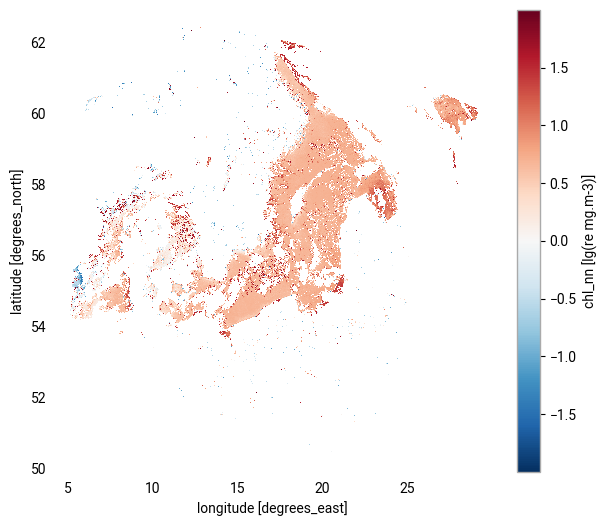

In [22]:
xr.open_dataset(result_path).chl_nn.plot()